# Checkpoint evaluation and error analysis

Load an existing checkpoint and evaluate development images without training. Existing published scores are summarized in `reports/baseline.md`. Evaluation does not log or overwrite MLflow results automatically. All scores use the detector’s current returned predictions (default score filtering, NMS, and detection cap), not exhaustive unfiltered proposals.

In [2]:
from pathlib import Path
import sys

project_dir = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / "voc_detection").is_dir() and (path / "configs").is_dir()
)
if str(project_dir) not in sys.path:
    sys.path.insert(0, str(project_dir))


## Load the saved epoch-2 model

In [3]:
import torch
from voc_detection.project import load_config, make_loader
from voc_detection.model import create_model
from voc_detection.evaluation import evaluate_model
from voc_detection.dataset import VOC_CLASSES

checkpoint_path = project_dir / "mlflow_local/checkpoints/d43c960633a7477e8e8d719de3a27338_epoch_2.pt"
checkpoint = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
config = {**load_config(), **checkpoint["config"]}
device = torch.device("cpu")
model = create_model(config["num_classes"], pretrained=False)
model.load_state_dict(checkpoint["model_state_dict"])
model = model.to(device)
dev_dataset, dev_loader = make_loader(config, "dev", shuffle=False)
print("Loaded epoch:", checkpoint["epoch"], "| Run:", checkpoint["mlflow_run_id"])


Loaded epoch: 2 | Run: d43c960633a7477e8e8d719de3a27338


## Evaluate development data
This runs inference on 1,144 images; it does not touch the final held-out official validation set.

In [4]:
evaluation = evaluate_model(model, dev_dataset, dev_loader, device)
dev_records = evaluation["records"]
print(f"Development mAP@0.5: {evaluation['map50']:.2%}")
display(evaluation["table"].sort_values("ap50", ascending=False).style.format({"ap50": "{:.2%}"}))


Evaluated 200/1144 images
Evaluated 400/1144 images
Evaluated 600/1144 images
Evaluated 800/1144 images
Evaluated 1000/1144 images
Evaluated 1144/1144 images
Development mAP@0.5: 70.66%


,ap50,objects
category,,
dog,86.29%,147
cat,86.14%,118
aeroplane,83.93%,81
train,83.40%,55
bus,80.44%,63
motorbike,78.93%,63
bicycle,78.87%,56
bird,77.41%,107
person,77.34%,895


## Inspect bottle predictions
Green boxes are annotations; orange boxes are predictions above a visualization-only threshold of 0.20. The first three matching images are examples, not a representative error-frequency estimate.

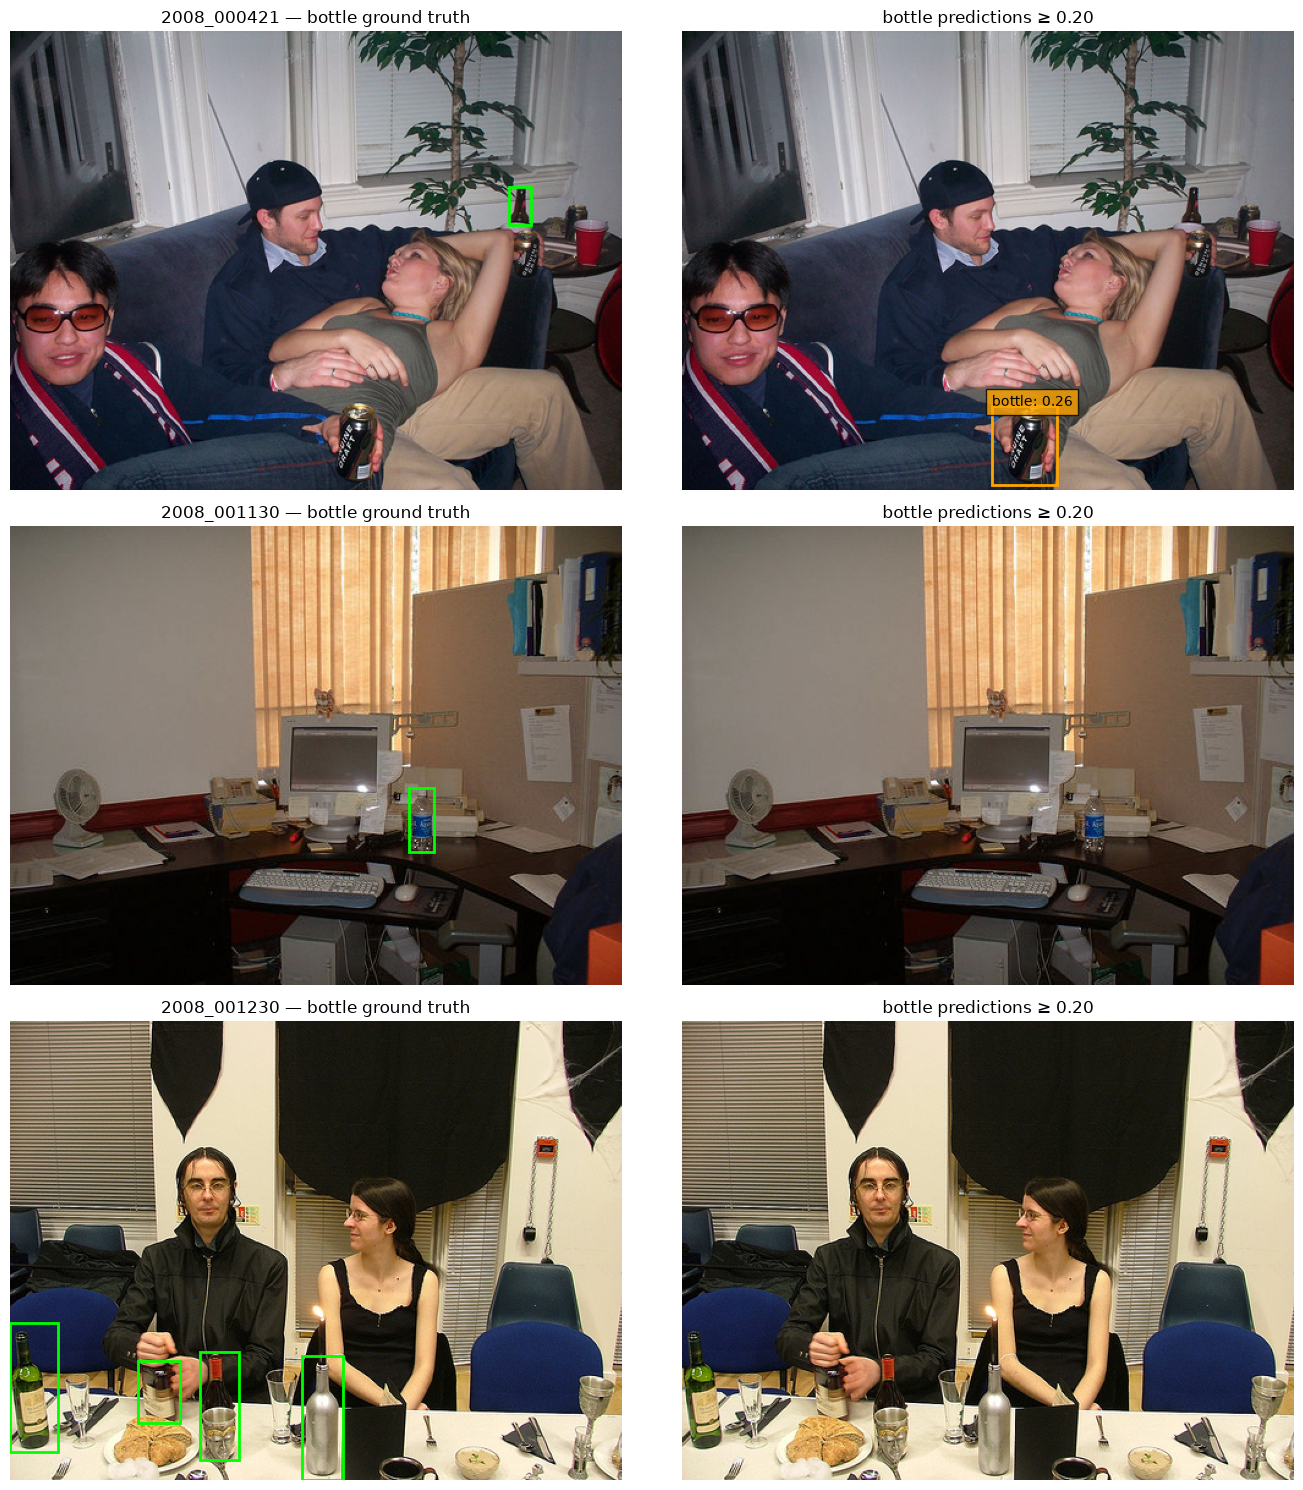

In [5]:
from voc_detection.visualization import plot_category_examples
import matplotlib.pyplot as plt

fig = plot_category_examples(
    records=dev_records,
    dataset=dev_dataset,
    category="bottle",
    threshold=0.20,
    limit=3,
)
plt.show()
